# 01 · Data and image features

**Task.** Each photo shows a chore — *Washing Dishes* or *Taking Out Trash* — that is either *Complete* or *Incomplete*:
4 classes, scored by **macro F1** (the mean of the four per-class F1 scores).

**Data.** 66 labelled training photos and 36 unlabelled test photos (Kaggle, private class competition).
External photos added later are listed in `data/external.csv` (notebook 04).

**How every experiment is scored (all notebooks).** 10 × repeated 5-fold cross-validation (CV) over the 66 training photos,
stratified by class. A photo and anything made from it (crops, rotations) always stay on the same side of a split,
external photos are only ever added to the training side, and only the 66 competition photos are scored.
With only 66 photos one split is noisy, so the mean over 10 repeats is reported; differences under about 0.02 are noise.

In [1]:
import numpy as np, pandas as pd
import common as c
pd.set_option('display.width', 200)

In [2]:
train, test = c.competition()
print(len(train), "training photos,", len(test), "test photos")
train.label.value_counts().rename("photos")

66 training photos, 36 test photos


label
Taking Out Trash|Incomplete    20
Washing Dishes|Complete        17
Washing Dishes|Incomplete      16
Taking Out Trash|Complete      13
Name: photos, dtype: int64

Two examples of each class:

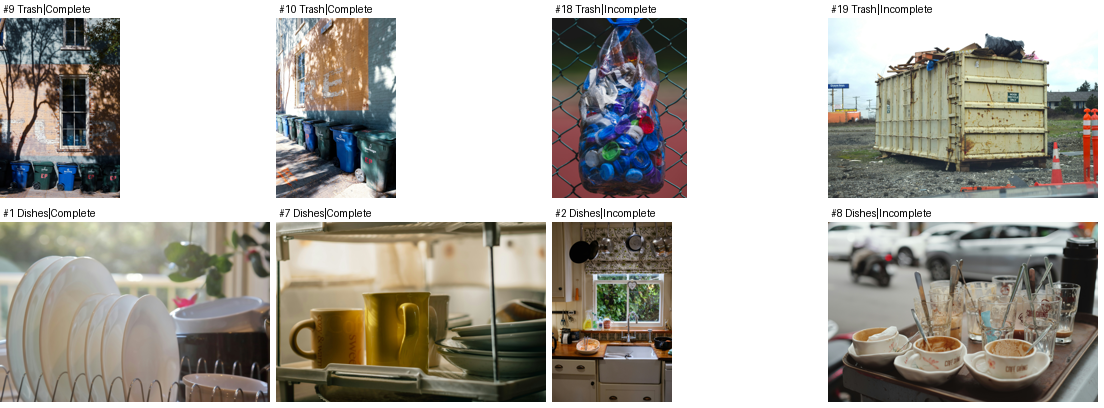

In [3]:
ex = train.groupby("label").head(2).sort_values("label")
c.show(ex.id.tolist(), [l.replace("Washing Dishes", "Dishes").replace("Taking Out Trash", "Trash") for l in ex.label], cols=4)

## Image features (embeddings)

Every photo is turned into a fixed-length vector of numbers (an *embedding*) by a pretrained image model; the
classifiers in the next notebooks learn only from these vectors. Five pretrained models were compared:

| name | model | trained on |
|---|---|---|
| `dinov2_l` | DINOv2 ViT-L/14 (Oquab et al., 2023) | 142M images, self-supervised |
| `siglip_so400m` | SigLIP SO400M (Zhai et al., 2023) | WebLI image–text pairs |
| `eva02_l` | EVA-02-CLIP ViT-L/14 | image–text pairs |
| `vith14_laion` | OpenCLIP ViT-H/14 | LAION-2B image–text pairs |
| `vitl14_openai` | CLIP ViT-L/14 (Radford et al., 2021) | OpenAI image–text pairs |

`extract_features.py` encodes each photo, its mirror image and 5 crops (four corners + centre, 2/3 of the photo) and
caches them in `features/<model>.npz`; only photos not yet in the cache are encoded. It is slow (minutes per model),
so it is run once from the command line: `python extract_features.py`. For DINOv2 the vector is the class token next to
the mean patch token (2 × 1024 = 2048 numbers). "Full view" in later notebooks = photo and mirror embeddings averaged.

In [4]:
rows = []
for b in c.BACKBONES:
    z = np.load(c.FEAT / f"{b}.npz")
    rows.append({"model": b, "photos cached": len(z["ids"]), "numbers per photo": z["img"].shape[1],
                 "views": "photo, mirror, 5 crops"})
pd.DataFrame(rows)

,model,photos cached,numbers per photo,views
0,dinov2_l,209,2048,"photo, mirror, 5 crops"
1,siglip_so400m,209,1152,"photo, mirror, 5 crops"
2,eva02_l,209,768,"photo, mirror, 5 crops"
3,vith14_laion,209,1024,"photo, mirror, 5 crops"
4,vitl14_openai,209,768,"photo, mirror, 5 crops"
